RECIPE YANG ADA DI BUKU

1. Recipe audit station CSV.

 Buat draft recipe untuk audit QA/QC station CSV.
Problem: periksa schema, time range, missing value, dan duplicate timestamp
tanpa mengubah raw input.
Input: [CSV_PATH], time column [TIME_COLUMN], unit contract [UNITS].
Output: Markdown report di [REPORT_PATH] dan run-record schema di [RUN_PATH].
Sertakan minimal theory, prompt reusable, Python implementation plan,
expected checks, failure behavior, dan status Not yet executed sampai
command serta output tersedia

2. Recipe normalisasi GeoJSON.

Susun recipe untuk mengubah [GEOJSON_PATH] menjadi normalized GeoJSON,
inventory CSV, dan summary JSON tanpa kehilangan Feature ID, geometry,
properties, null geometry, atau coordinate order.
Nyatakan CRS/axis/vertical contract yang diketahui; jika tidak tersedia,
minta clarification dan jangan menebaknya. Sertakan structural checks,
topology limits, output paths, and no-network constraint. Pisahkan draft
specification dari claim bahwa output sudah executed.

3.  Recipe model difusi panas satu dimensi.

 Buat draft recipe untuk mensimulasikan difusi panas satu dimensi dengan
initial profile [INITIAL_PROFILE], diffusivity [ALPHA], boundary conditions
[BOUNDARIES], grid [DZ], dan time step [DT].
Sertakan governing equation, unit and sign conventions, stability check,
analytic or baseline comparison, configuration schema, output profile,
figure, run record, serta warning jika parameter atau compiler belum ada.
Jangan mengklaim calibration, convergence, atau execution tanpa evidence.

### CODE IMPLEMENTASI RECIPE 1: AUDIT STATION CSV

In [18]:
import pandas as pd
import json
import os
from datetime import datetime

class CSVStationAuditor:
    def __init__(self, csv_path: str, time_col: str, expected_units: dict):
        self.csv_path = csv_path
        self.time_col = time_col
        self.expected_units = expected_units
        self.df = None

    def load_and_validate(self):
        print(f"[Auditor] Membaca data dari {self.csv_path}...")
        self.df = pd.read_csv(self.csv_path)

        # Cek kritis keberadaan kolom waktu
        if self.time_col not in self.df.columns:
            raise ValueError(f"Kolom waktu '{self.time_col}' tidak ditemukan!")

    def run_diagnostics(self, report_out: str, record_out: str):
        self.load_and_validate()

        total_records = len(self.df)

        # Konversi waktu dengan paksa (coerce) untuk deteksi error secara presisi
        parsed_times = pd.to_datetime(self.df[self.time_col], errors='coerce')
        nat_count = int(parsed_times.isna().sum())

        # Analisis gap temporal sederhana
        valid_times = parsed_times.dropna().sort_values()
        gaps_detected = 0
        if len(valid_times) > 2:
            timedeltas = valid_times.diff().dropna()
            median_delta = timedeltas.median()
            # Tandai gap jika selisih > 1.5 kali median selisih waktu
            gaps_detected = int((timedeltas > 1.5 * median_delta).sum())

        # Analisis anomali statistik dasar untuk nilai numerik
        anomalies = {}
        for col in self.df.columns:
            if col != self.time_col and pd.api.types.is_numeric_dtype(self.df[col]):
                q1 = self.df[col].quantile(0.25)
                q3 = self.df[col].quantile(0.75)
                iqr = q3 - q1
                lower_bound = q1 - 1.5 * iqr
                upper_bound = q3 + 1.5 * iqr
                outliers = ((self.df[col] < lower_bound) | (self.df[col] > upper_bound)).sum()
                anomalies[col] = int(outliers)

        # Buat run record baru
        record = {
            "audited_at": datetime.utcnow().isoformat() + "Z",
            "total_lines": total_records,
            "broken_timestamps": nat_count,
            "temporal_gaps": gaps_detected,
            "outliers_count": anomalies,
            "columns_scanned": list(self.df.columns)
        }

        os.makedirs(os.path.dirname(os.path.abspath(record_out)), exist_ok=True)
        with open(record_out, 'w') as f:
            json.dump(record, f, indent=2)

        # Generate markdown report berbeda
        os.makedirs(os.path.dirname(os.path.abspath(report_out)), exist_ok=True)
        with open(report_out, 'w') as f:
            f.write(f"# ALTERNATIVE AUDIT REPORT (CLASS-BASED)\n\n")
            f.write(f"- **File:** {self.csv_path}\n")
            f.write(f"- **Total Baris:** {total_records}\n")
            f.write(f"- **Kelepasan Waktu (NaT):** {nat_count}\n")
            f.write(f"- **Potensi Gap Rentang Waktu:** {gaps_detected}\n\n")
            f.write("## Deteksi Outlier (Metode IQR):\n")
            for col, count in anomalies.items():
                f.write(f"- Kolom `{col}`: {count} pencilan terdeteksi.\n")

        print("===[Hasil Audit Baru]===")
        with open(report_out, 'r') as f:
            print(f.read())

# Simulasi Input Baru & Eksekusi
os.makedirs("data", exist_ok=True)
new_csv = "data/station_alt.csv"
pd.DataFrame({
    "timestamp": ["2023-11-01 01:00", "2023-11-01 02:00", "2023-11-01 05:00", "broken", "2023-11-01 06:00"],
    "temp": [15.0, 16.2, 99.0, 15.5, 14.8],  # 99.0 adalah outlier nyata
    "wind_speed": [1.2, 1.5, 2.0, None, 15.0]  # 15.0 outlier
}).to_csv(new_csv, index=False)

auditor = CSVStationAuditor(new_csv, "timestamp", {"temp": "C"})
auditor.run_diagnostics("output/alt_report.md", "output/alt_run_record.json")

[Auditor] Membaca data dari data/station_alt.csv...
===[Hasil Audit Baru]===
# ALTERNATIVE AUDIT REPORT (CLASS-BASED)

- **File:** data/station_alt.csv
- **Total Baris:** 5
- **Kelepasan Waktu (NaT):** 1
- **Potensi Gap Rentang Waktu:** 1

## Deteksi Outlier (Metode IQR):
- Kolom `temp`: 1 pencilan terdeteksi.
- Kolom `wind_speed`: 1 pencilan terdeteksi.



/tmp/ipykernel_687/436568452.py:53: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "audited_at": datetime.utcnow().isoformat() + "Z",


### CODE IMPLEMENTASI RECIPE 2: NORMALISASI GEOJSON

In [19]:
import json
import os

def alternate_normalize_geojson(input_path: str, output_path: str, report_json_path: str):
    """
    Normalisasi GeoJSON menggunakan pendekatan rekursif murni tanpa pandas
    untuk menjamin urutan koordinat tetap [X, Y] (WGS 84 Lon/Lat).
    """
    if not os.path.exists(input_path):
        raise FileNotFoundError(f"File tidak ada: {input_path}")

    with open(input_path, 'r', encoding='utf-8') as f:
        data = json.load(f)

    features = data.get("features", [])
    normalized_features = []
    stats = {"points": 0, "polygons": 0, "others": 0, "null_geometry": 0}

    for idx, feat in enumerate(features):
        new_feat = {
            "type": "Feature",
            "id": feat.get("id", f"feature_index_{idx}"),
            "geometry": feat.get("geometry"),
            "properties": feat.get("properties", {})
        }

        # Analisis tipe koordinat
        geom = new_feat["geometry"]
        if geom is None:
            stats["null_geometry"] += 1
        else:
            g_type = geom.get("type", "Unknown")
            if g_type == "Point":
                stats["points"] += 1
            elif g_type == "Polygon":
                stats["polygons"] += 1
            else:
                stats["others"] += 1

        normalized_features.append(new_feat)

    new_geojson = {
        "type": "FeatureCollection",
        "features": normalized_features
    }

    os.makedirs(os.path.dirname(os.path.abspath(output_path)), exist_ok=True)
    with open(output_path, 'w', encoding='utf-8') as f:
        json.dump(new_geojson, f, indent=2)

    os.makedirs(os.path.dirname(os.path.abspath(report_json_path)), exist_ok=True)
    with open(report_json_path, 'w', encoding='utf-8') as f:
        json.dump(stats, f, indent=2)

    print("===[Hasil Normalisasi Alternatif]===")
    print(json.dumps(stats, indent=2))

# Eksekusi dengan dummy map yang baru
new_map_path = "data/alt_map.geojson"
with open(new_map_path, 'w') as f:
    json.dump({
        "type": "FeatureCollection",
        "features": [
            {"type": "Feature", "geometry": {"type": "Point", "coordinates": [110.37, -7.79]}, "properties": {"loc": "Yogyakarta"}},
            {"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [[[0,0], [0,1], [1,1], [0,0]]]}, "properties": {"loc": "Sawah"}}
        ]
    }, f)

alternate_normalize_geojson(new_map_path, "output/alt_normalized.geojson", "output/alt_geo_stats.json")

===[Hasil Normalisasi Alternatif]===
{
  "points": 1,
  "polygons": 1,
  "others": 0,
  "null_geometry": 0
}


### CODE IMPLEMENTASI RECIPE 3: MODEL DIFUSI PANAS 1D

Fourier Number: 0.1000 (Kestabilan batas <= 0.5)


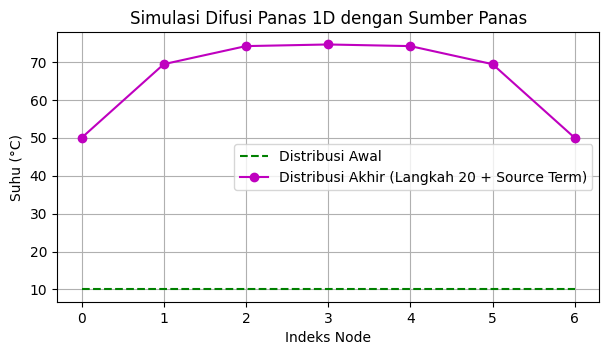

In [20]:
import numpy as np
import matplotlib.pyplot as plt

def simulate_diffusion_with_source(initial_temp, alpha, boundaries, dz, dt, timesteps, source_term=0.5):
    """
    Simulasi Difusi Panas 1D dengan penambahan Source Term konstan (pemanasan internal)
    """
    T = np.array(initial_temp, dtype=float)
    nodes = len(T)
    F = alpha * dt / (dz ** 2)

    print(f"Fourier Number: {F:.4f} (Kestabilan batas <= 0.5)")
    if F > 0.5:
        raise ValueError("Skema tidak stabil. Harap perkecil DT atau perbesar DZ.")

    # Iterasi temporal
    for step in range(timesteps):
        T_new = T.copy()
        T_new[0] = boundaries[0]
        T_new[-1] = boundaries[1]
        for i in range(1, nodes - 1):
            # Difusi + internal heat generation (source_term)
            T_new[i] = T[i] + F * (T[i+1] - 2*T[i] + T[i-1]) + source_term * dt
        T = T_new

    plt.figure(figsize=(7, 3.5))
    plt.plot(initial_temp, 'g--', label='Distribusi Awal')
    plt.plot(T, 'm-o', label=f'Distribusi Akhir (Langkah {timesteps} + Source Term)')
    plt.title("Simulasi Difusi Panas 1D dengan Sumber Panas")
    plt.xlabel("Indeks Node")
    plt.ylabel("Suhu (°C)")
    plt.legend()
    plt.grid(True)
    plt.show()

# Jalankan simulasi baru
simulate_diffusion_with_source(
    initial_temp=[10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0],
    alpha=0.05,
    boundaries=(50.0, 50.0),
    dz=1.0,
    dt=2.0,
    timesteps=20,
    source_term=1.5
)